As said in README, in this notebook I will cover the three issues of model that we used before. And after solving these three issues, the loss function should be lowered by some extent, though maybe not dramatically. The stats of the loss function on train and dev will be attached in the end (since we do not usually touch the test set)

## Preparation

In [1]:
import torch
import math
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

# read file
words = open('../names.txt', 'r').read().splitlines()
words[:10]

# mapping from letters to numbers and reverse
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos) # 27

# turning the dataset into the structure of [input] [desired output]
block_size = 3 
X, Y = [], []
for word in words:
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

# split the dataset (tr/dev/ts) (80/10/10)
def build_dataset(words):
    block_size = 3
    X, Y = [], [] 
    for word in words:
        # print(word)
        context = [0] * block_size 
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '------>', itos[ix])
            context = context[1:] + [ix] 
    X = torch.tensor(X) 
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1]) # 80%
Xdev, Ydev = build_dataset(words[n1: n2]) # 10%
Xts, Yts = build_dataset(words[n2:]) # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


The cell below define a function that is used for get the loss function of the whole tr/dev dataset more easily. 

In [4]:
@torch.no_grad() # this decorator disables gradient tracking
# decorator only affects the function defined directly below it
def split_loss(split): # split is either train, val, or test
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    emb = C[x] # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
    h = torch.tanh(embcat @ W1 + b1) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, voacb_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

# What we had in L3_notes

In [39]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g)
b1 = torch.randn(n_hidden,                          generator = g)
W2 = torch.randn((n_hidden, vocab_size),            generator = g)
b2 = torch.randn(vocab_size,                        generator = g)
parameters = [C, W1, b1, W2, b2]
print(sum([parameter.nelement() for parameter in parameters]))
for parameter in parameters:
    parameter.requires_grad = True

11897


In the code below I added h_initialization and hpreact_initialization. This is irrelevant to the process of the training, just a variable created for us to inspect of the distribution of value of h after activation upon activation.

      1/ 200000: 27.8817
  10000/ 200000: 2.7073
  20000/ 200000: 2.0407
  30000/ 200000: 2.3638
  40000/ 200000: 2.2808
  50000/ 200000: 2.4303
  60000/ 200000: 1.7856
  70000/ 200000: 1.9982
  80000/ 200000: 2.4749
  90000/ 200000: 2.2837
 100000/ 200000: 1.9924
 110000/ 200000: 2.0996
 120000/ 200000: 2.1612
 130000/ 200000: 2.1826
 140000/ 200000: 1.9403
 150000/ 200000: 2.4570
 160000/ 200000: 2.1866
 170000/ 200000: 1.7776
 180000/ 200000: 1.6747
 190000/ 200000: 2.1325
 200000/ 200000: 2.4201
train 2.1264491081237793
val 2.169877767562866


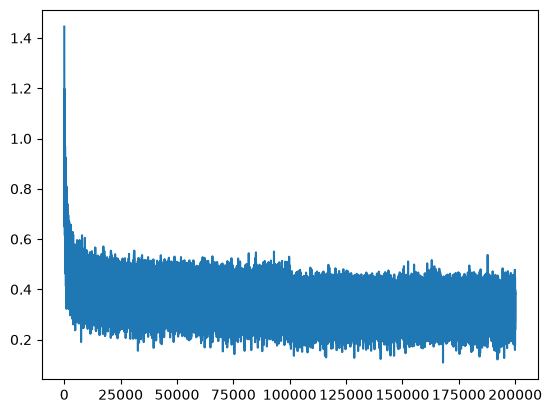

In [40]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] 

    # forward pass
    emb = C[Xb]
    embcat = emb.view(batch_size, -1)
    hpreact = embcat @ W1 + b1
    h = torch.tanh(hpreact)
    if i == 0:
        hpreact_initialization = hpreact
        h_initialization =  h
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats:
    if i == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    if (i+1) % 10000 == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())

# plot the loss over time
plt.plot(lossi)
# check the loss for tr and dev
split_loss('train')
split_loss('val')

# Issues 

### Great loss function upon initialization

The first reflection looking at the graph of loss function over time is that the loss function is too great at first, which is about 27.88. 

So here we want to verify whether the vaue is indeed too great.

Our predicted loss function value rests on the assumption that the probability predicted for all possible character is 1/27. And let us see the supposed value of loss function if all characters have the same chance of being predicted. 

In [26]:
# batch_size is 32, and vocab_size is 27 here
probs = torch.ones(batch_size) * (1/vocab_size)
loss = -probs.log().mean()
print(loss)

tensor(3.2958)


In other words, the supposed loss function upon initialization should be about 3.2958, but not as high as 27. 

And in the actual training, we do not directly get the probs, but instead we get logits. With a little bit of math, it is easy to realize that as long as the logits are all the same upon initialization, then the probabilities for each characters should be same too. Here, we just arbitrarily decide that the logits should all be centered around 0, since it is easier to implement than the other numbers. Let's test this guess:

In [27]:
logits = torch.zeros(batch_size)
counts = logits.exp()
probs = counts/vocab_size
loss = -probs.log().mean()
print(loss)

tensor(3.2958)


Therefore, the problem is that the logits upon initialization deviates too much from each other, and we just need to squash them all toward 0. 

### Distribution of activation of the hidden layer upon initialization

(array([2069.,  144.,  106.,   82.,   59.,   56.,   43.,   31.,   43.,
          26.,   16.,   38.,   16.,   32.,   24.,   14.,   28.,   27.,
          26.,   19.,   24.,   26.,   30.,   14.,   19.,   19.,   22.,
          26.,   18.,   12.,   10.,   33.,   27.,   32.,   17.,   24.,
          30.,   22.,   26.,   29.,   26.,   40.,   29.,   41.,   49.,
          64.,   62.,  100.,  188., 2442.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

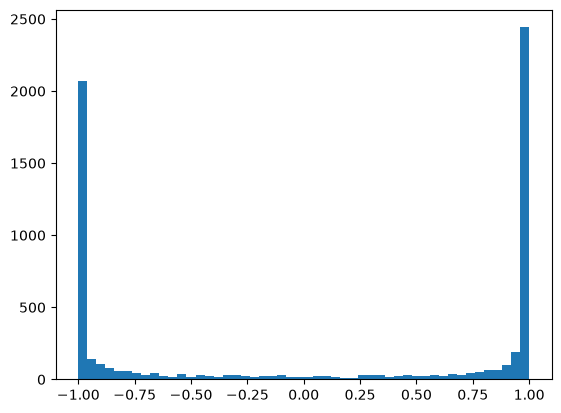

In [41]:
plt.hist(h_initialization.view(-1).tolist(), 50) # 50 is the number of bins

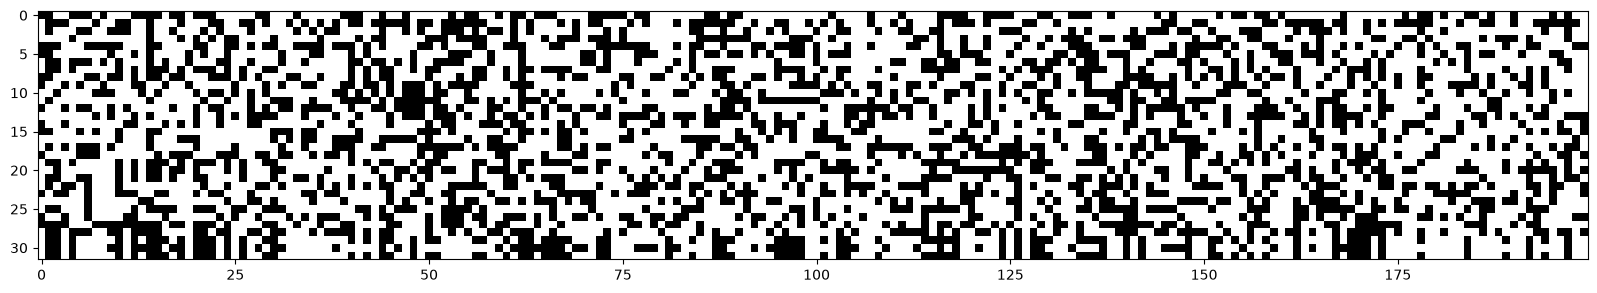

In [44]:
plt.figure(figsize=(20, 10))
plt.imshow(h_initialization.abs() > 0.99, cmap = 'gray', interpolation = 'nearest')
# h.abs() is a boolean tensor, and the grid is going to be white if it is true and black if false

Very obviously, almost all the entries in the matrix h upon initialization concentrate at the two ends of the graph (you can also see that form the heat map). The problem with this phenomenon is that where the value of tanh function is close to -1 or 1, its derivative is close to 0 as well. As a result of that, when the computer does back propogation, it will wrongly perceive that the value of these entries in h does not affect the final result by a lot, and that will moreover lead to that the weights, or the value of the parameters will not be changed by a lot. 

Especially, when there is a column that is completely white, this neuron is virtually dead since it cannot learn anything, which is luckily not the case in this situation. 

Side notes: not only should someone be careful with a gradient too small which leads to no 'learning', he should also be careful with a gradient too big, since in that case, if the learning rate is too big, the parameters will explode toward a position where the gradient is virtually zero, resulting in a consequence similar to knockout, premanent brain damage. 

Now we try to find the reason why the values of h concentrate at the two ends: hpreact

(array([  2.,   2.,   1.,   4.,   2.,   4.,   6.,  15.,   5.,  25.,  32.,
         49.,  56.,  59.,  92., 119., 134., 197., 195., 221., 257., 275.,
        297., 341., 353., 375., 369., 349., 358., 362., 271., 312., 229.,
        206., 190., 167.,  87., 111.,  72.,  55.,  41.,  22.,  23.,  18.,
         17.,   8.,   5.,   7.,   2.,   1.]),
 array([-19.05793762, -18.31571915, -17.57350067, -16.8312822 ,
        -16.08906372, -15.34684525, -14.60462677, -13.86240829,
        -13.12018982, -12.37797134, -11.63575287, -10.89353439,
        -10.15131592,  -9.40909744,  -8.66687897,  -7.92466049,
         -7.18244202,  -6.44022354,  -5.69800507,  -4.95578659,
         -4.21356812,  -3.47134964,  -2.72913116,  -1.98691269,
         -1.24469421,  -0.50247574,   0.23974274,   0.98196121,
          1.72417969,   2.46639816,   3.20861664,   3.95083511,
          4.69305359,   5.43527206,   6.17749054,   6.91970901,
          7.66192749,   8.40414597,   9.14636444,   9.88858292,
         10.630801

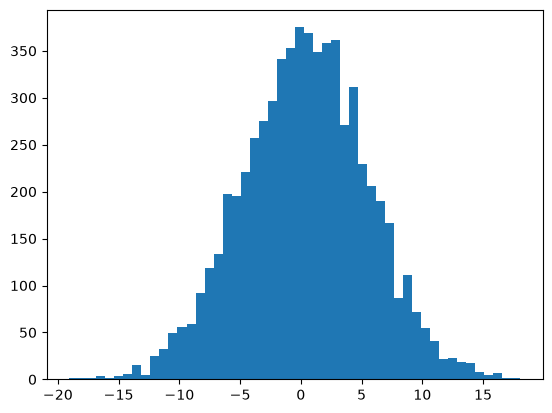

In [46]:
plt.hist(hpreact_initialization.view(-1).tolist(), 50)

And now, we can see the reason: most of the entries in hpreact_initialization are too far from 0 (an absolute value of 2.64665 will prove a tanh of 0.99). And the strategy to solve that issue is similar to the one above: pushing the entries toward 0. 

### Gaussian Distrbution not preserved

This issue is actually very similar to the second issue. In the second section of "issues", we prevented dead neuron and gradient explosion in the layer of tanh. However, people should not be careful with these two issues only in the tanh, but in other layers as well. 

However, it would be very annoying if we are to find the accurate scaling factor to obtain a Gaussian distribution. Therefore, it is appealing to have some formula for different kinds of layer. 

The easiest case is matrix multiplication:

A: mean -0.008930184878408909 | std 0.9979475140571594
A * B: mean -0.027516448870301247 | std 14.298720359802246


(array([4.67438103e-05, 0.00000000e+00, 4.67438103e-05, 9.34876206e-05,
        1.40231431e-04, 1.40231431e-04, 2.33719052e-04, 8.41388586e-04,
        8.41388586e-04, 1.49580193e-03, 1.40231431e-03, 3.17857910e-03,
        3.55252958e-03, 4.86135627e-03, 6.35715820e-03, 8.03993537e-03,
        9.11504301e-03, 1.21533907e-02, 1.58461517e-02, 1.84638051e-02,
        2.10347146e-02, 2.33251613e-02, 2.58025833e-02, 2.50546823e-02,
        2.59428147e-02, 2.67842033e-02, 2.72516414e-02, 2.72048976e-02,
        2.54286328e-02, 2.36991118e-02, 2.19228470e-02, 1.98661194e-02,
        1.52852260e-02, 1.66407965e-02, 1.34154736e-02, 1.08913078e-02,
        8.22691061e-03, 6.45064582e-03, 4.58089341e-03, 3.31881053e-03,
        2.33719052e-03, 1.91649622e-03, 1.77626479e-03, 1.07510764e-03,
        6.07669534e-04, 1.86975241e-04, 2.80462862e-04, 1.40231431e-04,
        0.00000000e+00, 1.40231431e-04]),
 array([-5.56235085e+01, -5.34841878e+01, -5.13448671e+01, -4.92055464e+01,
        -4.7066225

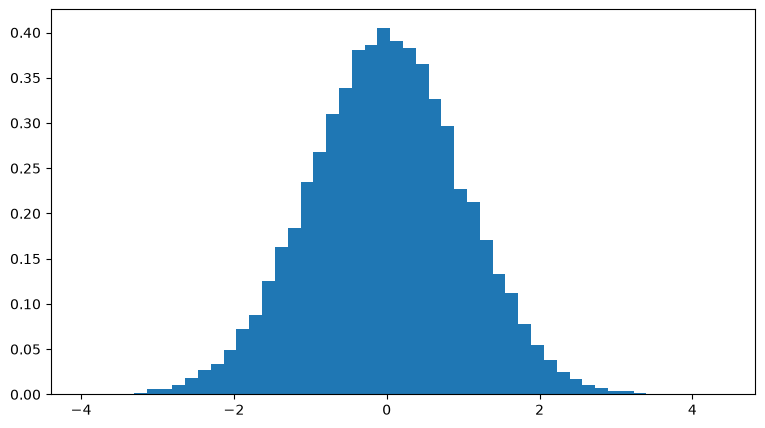

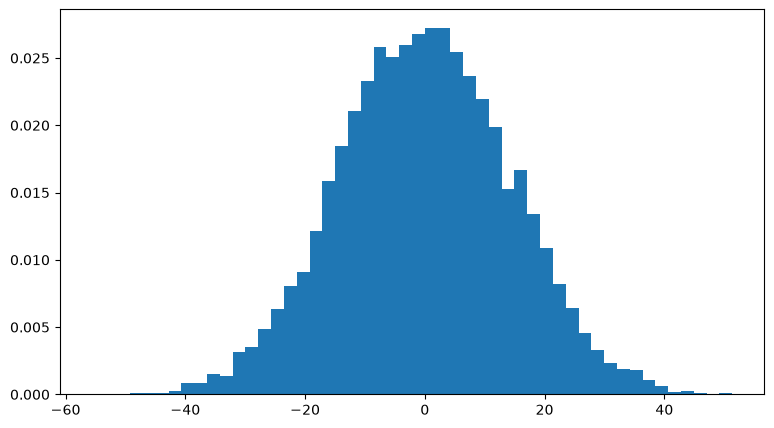

In [91]:
A = torch.randn((100, 200), generator = g)
B = torch.randn((200, 100), generator = g)
C = A @ B
print(f"A: mean {A.mean()} | std {A.std()}")
print(f"A * B: mean {C.mean()} | std {C.std()}")
plt.figure(figsize = (20, 5))
plt.subplot(121)
plt.hist(A.view(-1).tolist(), 50, density = True)
plt.figure(figsize = (20, 5))
plt.subplot(122)
plt.hist(C.view(-1).tolist(), 50, density = True)

Obviously, when A passing through the linear layer B, although the center of the graph does not move much, the standard deviation is scaling about 14 times, which is approximately the square root of 200, which is the fan_in of the linear layer. *fan_in is the number of input that a layer takes in*

And indeed, the theoretically value for scaling needed to preserve the Gaussian distribution is ```1 / sqrt(fan_in)```:

A: mean -0.004694708157330751 | std 1.0049059391021729
A * B: mean -0.010445675812661648 | std 1.0109237432479858


(array([0.0005959 , 0.        , 0.        , 0.        , 0.        ,
        0.0005959 , 0.        , 0.0005959 , 0.00119179, 0.00357537,
        0.00536306, 0.00476717, 0.01072612, 0.01728098, 0.02621941,
        0.03634964, 0.05482241, 0.07925414, 0.0989187 , 0.12930938,
        0.1406314 , 0.18055642, 0.21511837, 0.25802287, 0.30390684,
        0.37064717, 0.36051694, 0.39627068, 0.35992104, 0.43500391,
        0.37243485, 0.34442775, 0.3241673 , 0.29675609, 0.24133779,
        0.20558404, 0.19068665, 0.13884371, 0.09653511, 0.0846172 ,
        0.05422651, 0.04350039, 0.02741121, 0.01906866, 0.01310971,
        0.00774664, 0.00476717, 0.00119179, 0.00178769, 0.0005959 ]),
 array([-4.82867575, -4.66086116, -4.49304658, -4.325232  , -4.15741741,
        -3.98960283, -3.82178824, -3.65397366, -3.48615908, -3.31834449,
        -3.15052991, -2.98271533, -2.81490074, -2.64708616, -2.47927157,
        -2.31145699, -2.14364241, -1.97582782, -1.80801324, -1.64019866,
        -1.47238407, -1.30

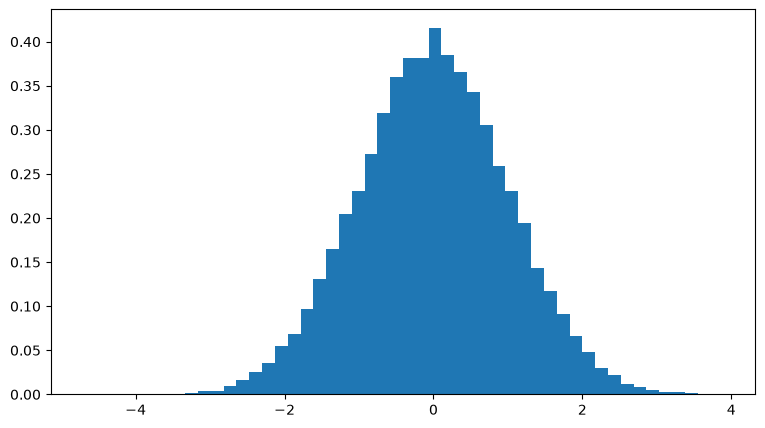

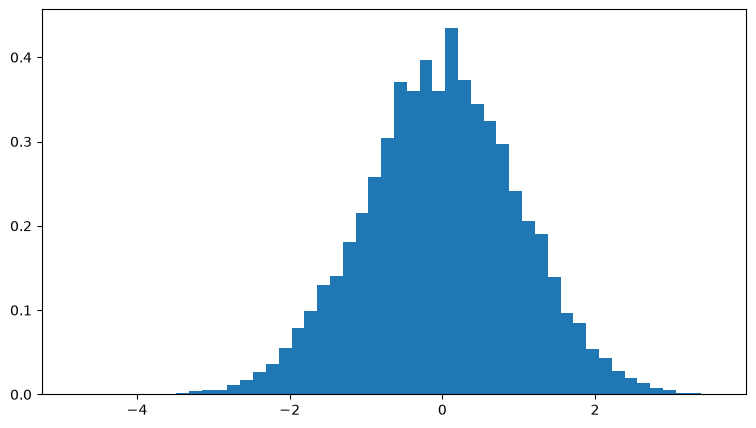

In [92]:
A = torch.randn((100, 200), generator = g)
B = torch.randn((200, 100), generator = g) * (1/200**0.5)
C = A @ B
print(f"A: mean {A.mean()} | std {A.std()}")
print(f"A * B: mean {C.mean()} | std {C.std()}")
plt.figure(figsize = (20, 5))
plt.subplot(121)
plt.hist(A.view(-1).tolist(), 50, density = True)
plt.figure(figsize = (20, 5))
plt.subplot(122)
plt.hist(C.view(-1).tolist(), 50, density = True)

Now the standard deviation of the two distribution is much more similar. 

However, that is just the simplest case for the linear layer. The case for those nonlinear activation layer like tanh or ReLU is much more complicated. 

For those nonlinear layers, they take into an array of values and squash them into a smaller range, therefore reducing the standard deviation. As a result, it is recommended to increase the scaling factor of the linear layer before the nonlinear layer, and the exactly increment of these sclaing factor for the linear layer depends on exact type of the nonlinear layer, as listed below: 

| Activation Function | Recommended Gain | Common Use |
|:---|:---:|:---|
| Linear / Identity | $1$ | Linear layers |
| Sigmoid | $1$ | Output layers |
| Tanh | $\frac{5}{3}$ | Hidden layers |
| ReLU | $\sqrt{2}$ | Deep neural networks, CNNs |
| Leaky ReLU | $\sqrt{\frac{2}{1+a^2}}$ | Preventing dead neurons |
| SELU | $\frac{3}{4}$ | Self-normalizing neural networks |

$$
\text{std} = \frac{\text{gain}}{\sqrt{\text{fan\_in}}}
$$

Where:

- $\text{gain}$ is determined by the activation function.
- $\text{fan\_in}$ is the number of input connections to a neuron.

And obviously in our case, we need to scale the standard initialized weights by ```(5/3) / sqrt(block_size * embd_size)```

# Great loss function upon initialization

As detailed in the first section in issues, we found the problem: the logits upon initialization deviate too much from each other, and our plan to just to squash them toward zero. 

However, we just want to do the squash upon initialization, but not during every otehr cycle since they may interfere with the backward propogation. 

With the formula by which we get logits, which is h @ W2 + b2, we can easily realize that in order to squash the logits toward zero, we just need to turn down the absolute value of the entries in W2 and change b2 to 0 (only upon initialization), as seen the code below:

In [99]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g)
b1 = torch.randn(n_hidden,                          generator = g)
# ------------ changed
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * 0.01
b2 = torch.zeros(vocab_size)
# ------------ changed
parameters = [C, W1, b1, W2, b2]
print(sum([parameter.nelement() for parameter in parameters]))
for parameter in parameters:
    parameter.requires_grad = True

11897


      1/ 200000: 3.2975
  10000/ 200000: 2.2180
  20000/ 200000: 2.1818
  30000/ 200000: 2.4370
  40000/ 200000: 2.0610
  50000/ 200000: 2.1110
  60000/ 200000: 2.2944
  70000/ 200000: 2.3321
  80000/ 200000: 2.5445
  90000/ 200000: 2.2256
 100000/ 200000: 2.0234
 110000/ 200000: 2.1165
 120000/ 200000: 2.1461
 130000/ 200000: 2.2769
 140000/ 200000: 2.3726
 150000/ 200000: 2.3932
 160000/ 200000: 2.3567
 170000/ 200000: 1.9042
 180000/ 200000: 1.6837
 190000/ 200000: 1.9273
 200000/ 200000: 2.4714
train 2.069837808609009
val 2.1326262950897217


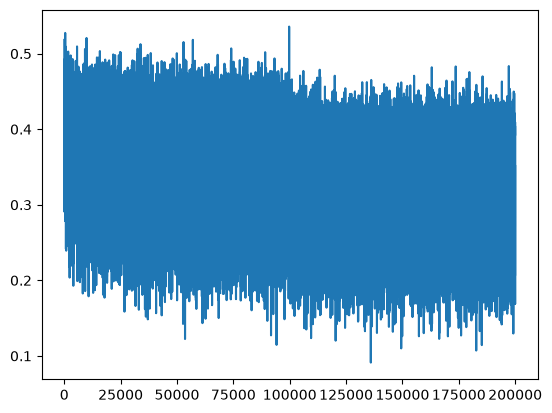

In [100]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] 

    # forward pass
    emb = C[Xb]
    embcat = emb.view(batch_size, -1)
    hpreact = embcat @ W1 + b1
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats:
    if i == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    if (i+1) % 10000 == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())

# plot the loss over time
plt.plot(lossi)
# check the loss for tr and dev
split_loss('train')
split_loss('val')

Obviously, issue solved. 

# Distribution of activation of the hidden layer upon initialization

As detailed in the second section in issues, we found the problem: hpreact deviate too much zero, which leads to virtually zero learning rate. 

Again, we just want to do the squash upon initialization, but not during every other cycle since they may interfere with the backward propogation. 

Since hpreact is obtained by embcat @ W1 + b1, we can simply scale down W1 and b1 by a lot. *Here we do not have to set b1 absolutely to zero since the existence of actual value in b1 can introduce some variability*. 

Side note: at the same time of pushing these entries to zero, we do not want them to be all close to zero either since that may lead to gradient explosion and kill the neurons, which is why i finally settle on the scaling of 0.18 for W1, since if it is too high it will still have the issue before, and if it is too small it may lead to gradient explosion. 

In [86]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator = g)
# ------------ changed
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 0.18
b1 = torch.randn(n_hidden,                          generator = g) * 0.01
# ------------ changed
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * 0.01
b2 = torch.zeros(vocab_size)
parameters = [C, W1, b1, W2, b2]
print(sum([parameter.nelement() for parameter in parameters]))
for parameter in parameters:
    parameter.requires_grad = True

11897


      1/ 200000: 3.2938
  10000/ 200000: 2.1919
  20000/ 200000: 2.0467
  30000/ 200000: 2.3817
  40000/ 200000: 1.9740
  50000/ 200000: 2.2589
  60000/ 200000: 2.2926
  70000/ 200000: 2.1135
  80000/ 200000: 2.4173
  90000/ 200000: 2.1125
 100000/ 200000: 1.9753
 110000/ 200000: 2.1409
 120000/ 200000: 2.1626
 130000/ 200000: 2.2300
 140000/ 200000: 2.2961
 150000/ 200000: 2.3836
 160000/ 200000: 2.2906
 170000/ 200000: 1.9597
 180000/ 200000: 1.7660
 190000/ 200000: 1.8525
 200000/ 200000: 2.2773
train 2.0381054878234863
val 2.1005306243896484


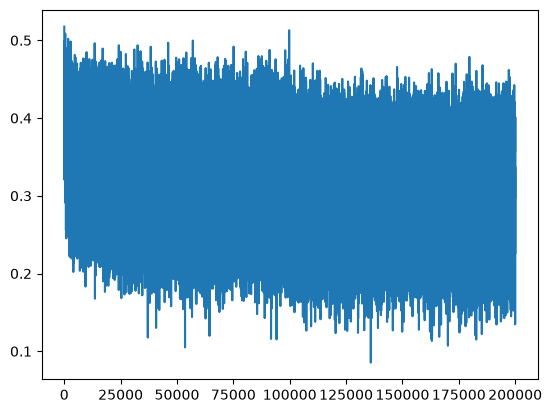

In [87]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] 

    # forward pass
    emb = C[Xb]
    embcat = emb.view(batch_size, -1)
    hpreact = embcat @ W1 + b1
    h = torch.tanh(hpreact)
    if i == 0:
        hpreact_initialization = hpreact
        h_initialization =  h
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats:
    if i == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    if (i+1) % 10000 == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
    # break

# plot the loss over time
plt.plot(lossi)
# check the loss for tr and dev
split_loss('train')
split_loss('val')

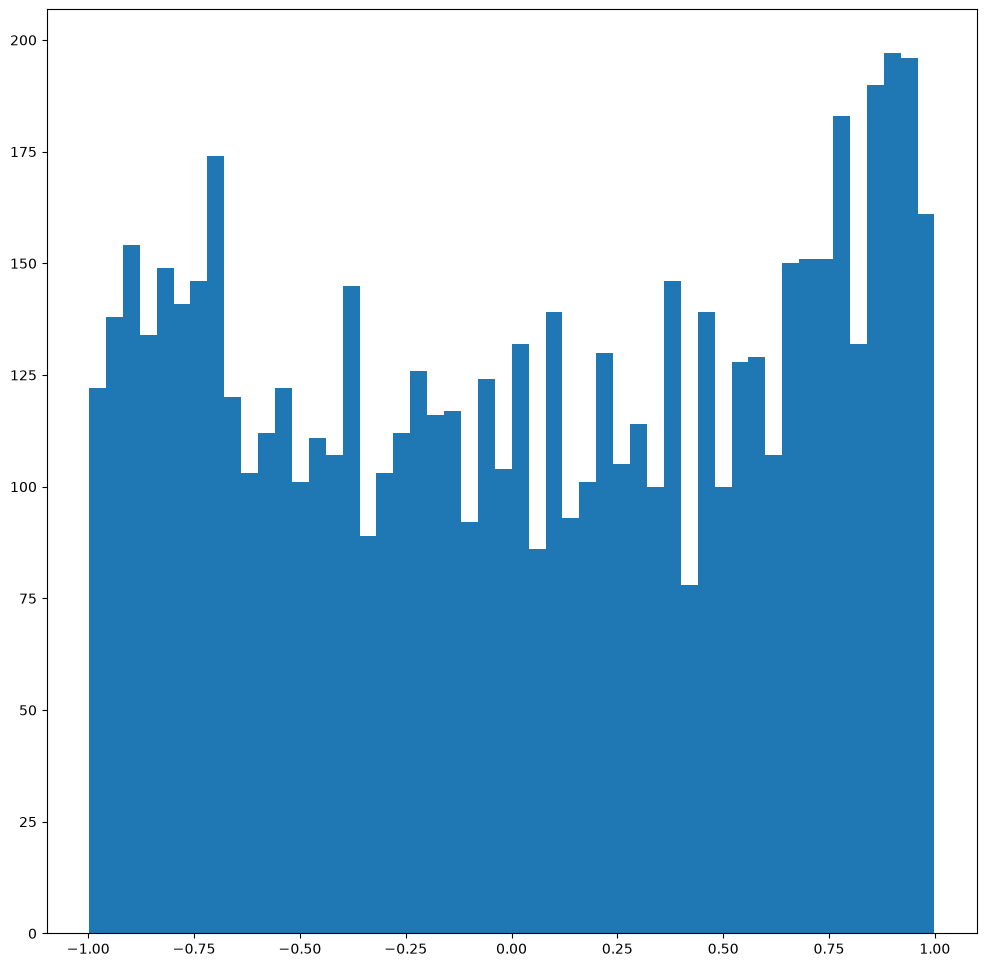

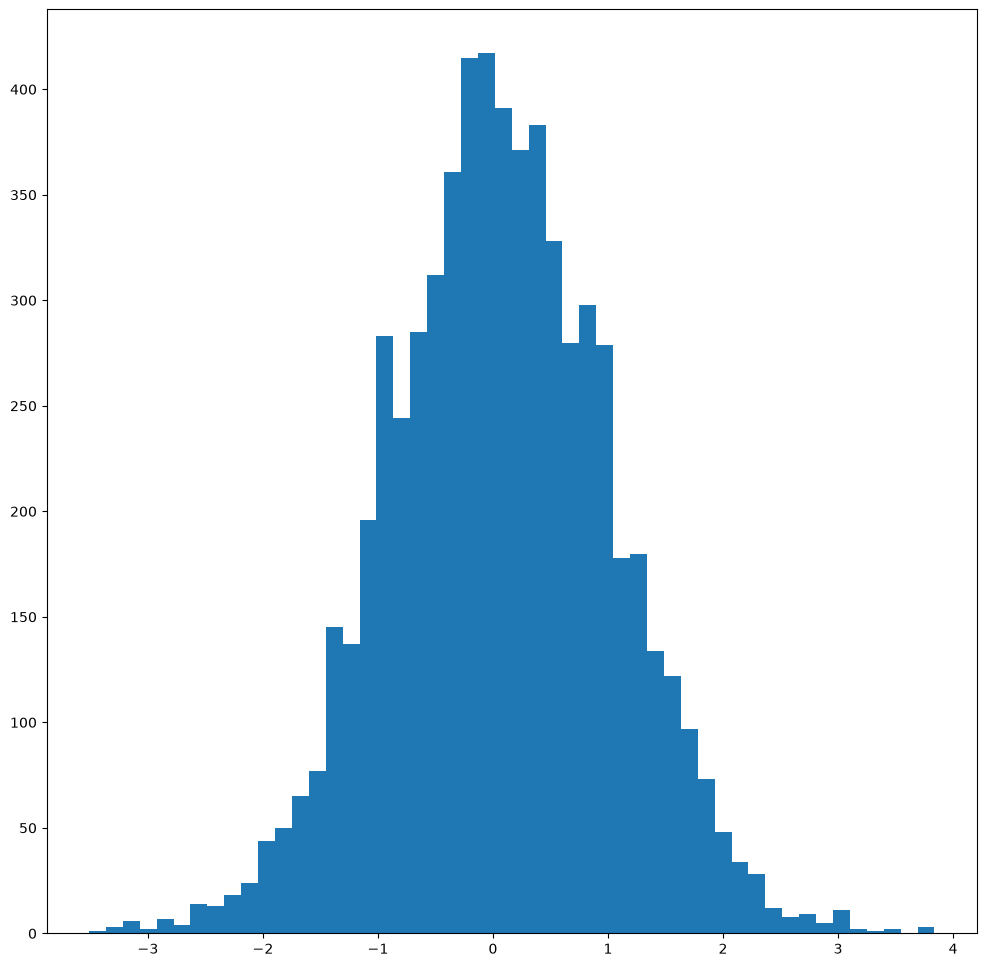

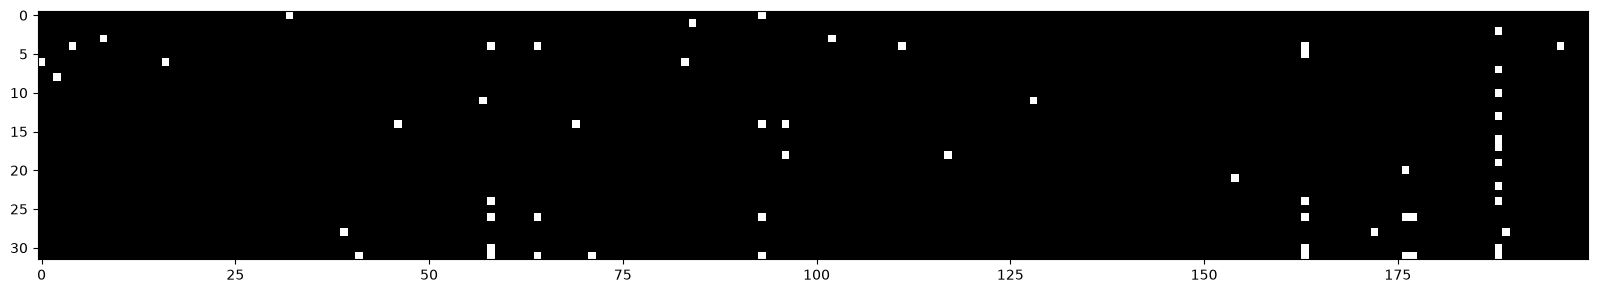

In [88]:
plt.figure(figsize=(12, 12))
plt.hist(h_initialization.view(-1).tolist(), 50)
plt.figure(figsize=(12, 12))
plt.hist(hpreact_initialization.view(-1).tolist(), 50)
plt.figure(figsize=(20, 10))
plt.imshow(h_initialization.abs() > 0.99, cmap = 'gray', interpolation = 'nearest')
# h.abs() is a boolean tensor, and the grid is going to be white if it is true and black if false

Obviously, issue solved. 

# Gaussian Distribution not preserved

As detailed in the third section of issues, we already found the problem and the way to fix it. Here we implement it by adding the additional scaling factor upon initialization (only upon initialization, again). 

This time, we are not just scaling the parameters by feeling, but with some deterministic calculation that we know to be right. 

Side notes: we do not change scaling of the bias because that does not affect the standard deviation upon initialization, which. is obviously. 

In [93]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator = g)
# ------------ changed
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 * (1/(n_embd * block_size)**0.5)
# ------------ changed
b1 = torch.randn(n_hidden,                          generator = g) * 0.01
# ------------ changed
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * (1/(n_hidden)**0.5)
# ------------ changed
b2 = torch.zeros(vocab_size)
parameters = [C, W1, b1, W2, b2]
print(sum([parameter.nelement() for parameter in parameters]))
for parameter in parameters:
    parameter.requires_grad = True

11897


      1/ 200000: 3.4884
  10000/ 200000: 2.1383
  20000/ 200000: 2.0708
  30000/ 200000: 2.2909
  40000/ 200000: 2.0088
  50000/ 200000: 2.2835
  60000/ 200000: 2.3512
  70000/ 200000: 2.1540
  80000/ 200000: 2.5495
  90000/ 200000: 2.1546
 100000/ 200000: 1.9762
 110000/ 200000: 2.1408
 120000/ 200000: 2.1580
 130000/ 200000: 2.3599
 140000/ 200000: 2.3836
 150000/ 200000: 2.3120
 160000/ 200000: 2.3404
 170000/ 200000: 1.9755
 180000/ 200000: 1.5704
 190000/ 200000: 1.9125
 200000/ 200000: 2.2900
train 2.0386407375335693
val 2.1030750274658203


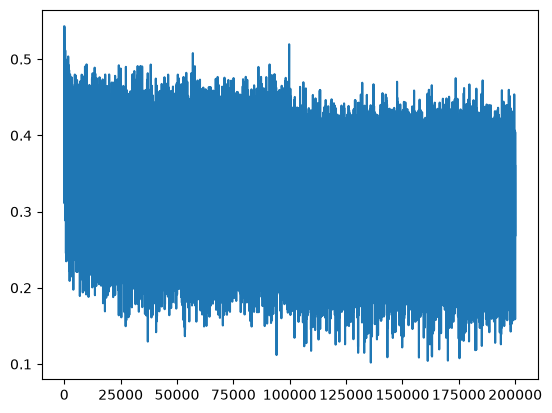

In [94]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construction
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator = g)
    Xb, Yb = Xtr[ix], Ytr[ix] 

    # forward pass
    emb = C[Xb]
    embcat = emb.view(batch_size, -1)
    hpreact = embcat @ W1 + b1
    h = torch.tanh(hpreact)
    if i == 0:
        hpreact_initialization = hpreact
        h_initialization =  h
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # back propogation
    for parameter in parameters:
        parameter.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for parameter in parameters:
        parameter.data -= lr * parameter.grad

    # tract stats:
    if i == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    if (i+1) % 10000 == 0:
        print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
    # break

# plot the loss over time
plt.plot(lossi)
# check the loss for tr and dev
split_loss('train')
split_loss('val')

# Loss Log

| Experiment | Train Loss | Validation Loss |
|:---|---:|---:|
| Before | 2.1264 | 2.1699 |
| Great loss function upon initialization | 2.0698 | 2.1326 |
| Distribution of activation of the hidden layer upon initialization | 2.0381 | 2.1005 |
| Gaussian distribution not preserved | 2.0386 | 2.1031 |

As seen from the difference between the fourth and fifth row, there is no improvement by solving the third issue. That is because the second issue basically covers the problems of the third issue, and since the neural network is fairly small, the stability issue does not cause a lot of troubles here. 